In [1]:
import h5py
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import label
from skimage import morphology
from skimage import measure
from scipy import ndimage as ndi

In [2]:
# ---------------------------------------------------------
# 2. COMPUTE J_parallel = dBy/dx - dBx/dy (FFT derivatives)
# ---------------------------------------------------------
def partial_x_fft(f, dx):
    nx, ny = f.shape
    kx = 2 * np.pi * np.fft.fftfreq(nx, d=dx)
    f_fft = np.fft.fft(f, axis=0)
    df_fft = 1j * kx[:, None] * f_fft
    return np.real(np.fft.ifft(df_fft, axis=0))

def partial_y_fft(f, dy):
    nx, ny = f.shape
    ky = 2 * np.pi * np.fft.fftfreq(ny, d=dy)
    f_fft = np.fft.fft(f, axis=1)
    df_fft = 1j * ky[None, :] * f_fft
    return np.real(np.fft.ifft(df_fft, axis=1))

def remove_small_regions(mask, min_area):
    """
    Remove connected components in a binary mask that
    have area smaller than min_area (in pixels).
    
    mask: 2D numpy array of dtype bool or int (0/1)
    min_area: minimum allowed area for a connected region
    """
    mask_bool = mask.astype(bool)

    # Label connected components
    labels = measure.label(mask_bool, connectivity=2)

    # Properties of labeled regions
    props = measure.regionprops(labels)

    # Start with an empty mask
    filtered = np.zeros_like(mask_bool)

    # Keep only components with area ≥ min_area
    for p in props:
        if p.area >= min_area:
            filtered[labels == p.label] = True

    return filtered.astype(int)

In [5]:
# ---------------------------------------------------------
# 1. LOAD DATA
# ---------------------------------------------------------
File_Bx = '/DATA/DEVESH/ApJ2015/Bx_ApJ_t42.h5'
File_By = '/DATA/DEVESH/ApJ2015/By_ApJ_t42.h5'

with h5py.File(File_Bx, 'r') as fBx, h5py.File(File_By, 'r') as fBy:
    data_Bx = fBx['DS1'][:].T
    data_By = fBy['DS1'][:].T


dx = dy = 0.125
J_par = partial_x_fft(data_By, dx) - partial_y_fft(data_Bx, dy)

threshold = np.quantile(np.abs(J_par), 0.9)
binary_mask = np.abs(J_par) > threshold


# ---------------------------------------------------------
# 5. MORPHOLOGICAL SMOOTHING
# ---------------------------------------------------------
struct = morphology.disk(5)

smoothed_mask = morphology.binary_opening(binary_mask, struct)
smoothed_mask = morphology.binary_closing(smoothed_mask, struct)
smoothed_mask = smoothed_mask.astype(int)

print("Binary mask stats:", np.unique(smoothed_mask, return_counts=True))

Binary mask stats: (array([0, 1]), array([4083801,  110503]))


In [3]:
#Lets Plot J_total

# 1. Read the HDF5 file
File_Bx = '/DATA/DEVESH/ApJ2015/Bx_ApJ_t42.h5'  # Replace with your file path
File_By = '/DATA/DEVESH/ApJ2015/By_ApJ_t42.h5'  # Replace with your file path
File_Bz = '/DATA/DEVESH/ApJ2015/Bz_ApJ_t42.h5'  # Replace with your file path

with h5py.File(File_Bx, 'r') as fBx, h5py.File(File_By, 'r') as fBy, h5py.File(File_Bz, 'r') as fBz:
    data_Bx = fBx['DS1'][:].T
    data_By = fBy['DS1'][:].T
    data_Bz = fBz['DS1'][:].T
    data_Jx = partial_y_fft(data_Bz,0.125)
    data_Jy = -partial_x_fft(data_Bz,0.125)
    data_Jz = partial_x_fft(data_By,0.125)-partial_y_fft(data_Bx,0.125)

J_squared = data_Jx**2 + data_Jy**2 + data_Jz**2

threshold = np.quantile(np.abs(J_squared), 0.9)
binary_mask = np.abs(J_squared) > threshold


# ---------------------------------------------------------
# 5. MORPHOLOGICAL SMOOTHING
# ---------------------------------------------------------
struct = morphology.disk(5)

smoothed_mask = morphology.binary_opening(binary_mask, struct)
smoothed_mask = morphology.binary_closing(smoothed_mask, struct)
smoothed_mask = smoothed_mask.astype(int)

print("Binary mask stats:", np.unique(smoothed_mask, return_counts=True))

Binary mask stats: (array([0, 1]), array([4070743,  123561]))


In [4]:
min_area = 300   # choose based on physical sheet size
cleaned_mask = remove_small_regions(smoothed_mask, min_area)

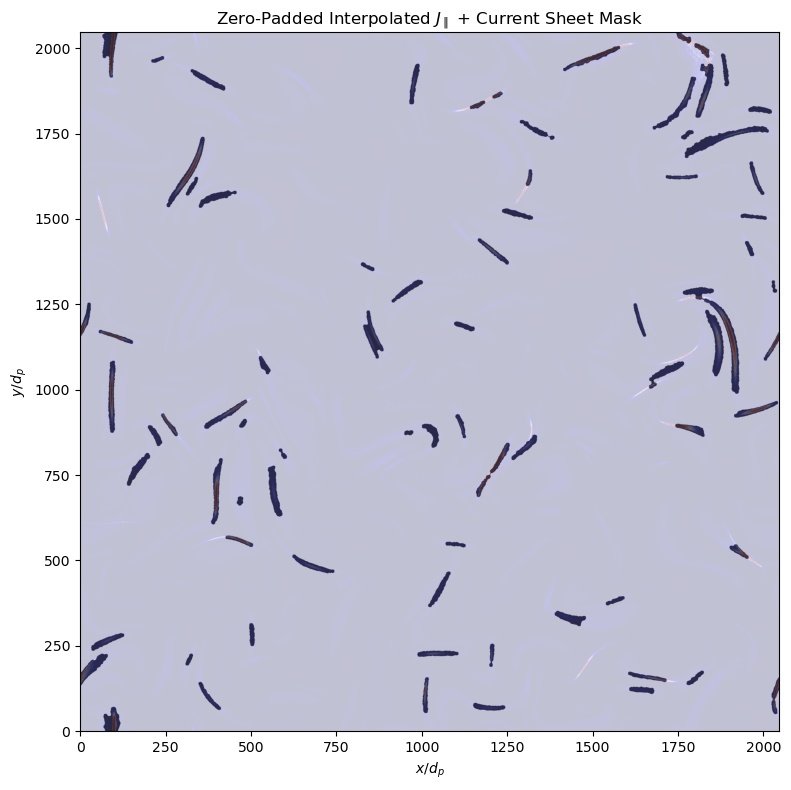

In [17]:
# ---------------------------------------------------------
# 6. PLOTTING
# ---------------------------------------------------------
plt.figure(figsize=(10, 8))
plt.imshow((J_squared).T, cmap='seismic', alpha=0.6, origin='lower', vmax=0.5)
plt.imshow(~cleaned_mask.T, cmap='gray', alpha=0.6, origin='lower')

plt.title(r'Zero-Padded Interpolated $J_\parallel$ + Current Sheet Mask')
plt.xlabel(r'$x/d_p$')
plt.ylabel(r'$y/d_p$')

plt.tight_layout()
plt.savefig("Jtotal_current_sheets_interpolated.png", dpi=300)
plt.show()

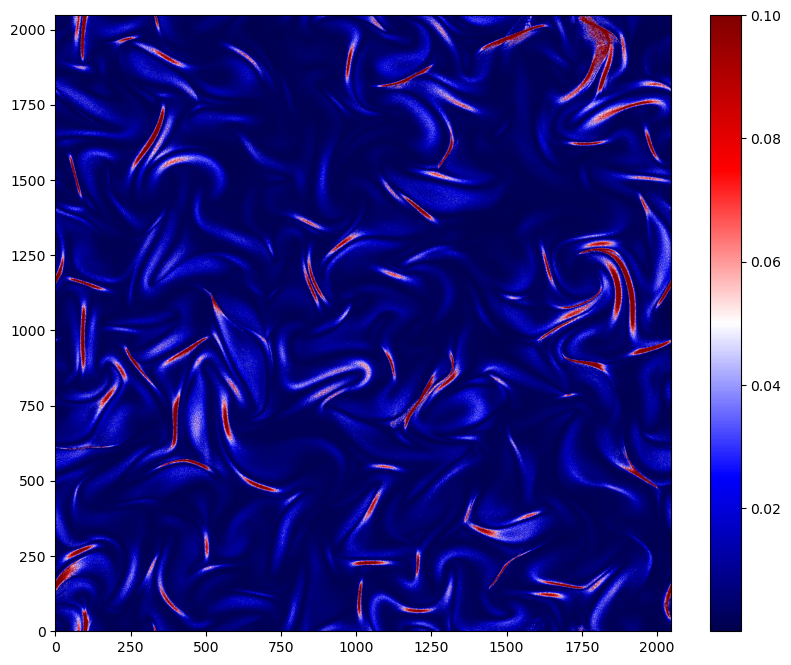

In [15]:
plt.figure(figsize=(10, 8))
plt.imshow((J_squared).T, cmap='seismic', origin='lower', vmax=0.1)
plt.colorbar()

In [11]:
# ---------------------------------------------------------
# FIND MAXIMUM J_par IN EACH CONNECTED REGION
# ---------------------------------------------------------

labeled_mask, num_features = label(cleaned_mask)
print("Regions found:", num_features)

max_coords = []
max_values = []

for i in range(1, num_features + 1):
    region_mask = (labeled_mask == i)
    region_vals = J_par[region_mask]

    if region_vals.size == 0:
        continue

    # Extreme value (max magnitude)
    max_pos = np.argmax(np.abs(region_vals))
    extreme_value = region_vals[max_pos]
    max_values.append(extreme_value)

    # Convert index → coordinates
    xs, ys = np.where(region_mask)
    max_coords.append((xs[max_pos], ys[max_pos]))

Regions found: 74


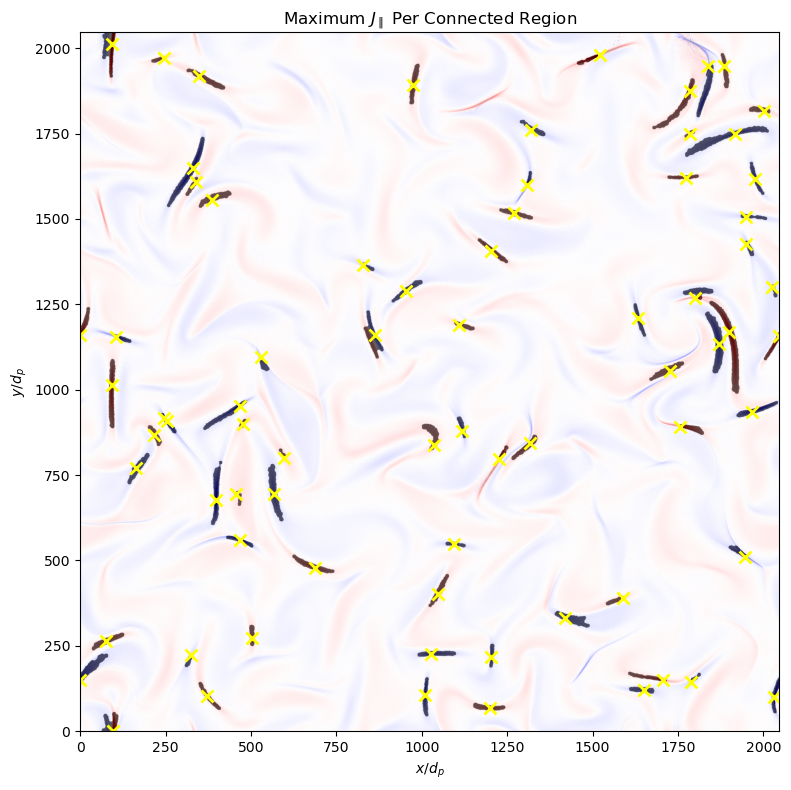

In [12]:
# ---------------------------------------------------------
# PLOT ORIGINAL FIELD + MASK + MAXIMUM POINTS
# ---------------------------------------------------------
plt.figure(figsize=(10, 8))

plt.imshow((J_par).T, cmap='seismic',
           origin='lower', vmin=-1.5, vmax=1.5)

plt.imshow(~cleaned_mask.T, cmap='gray', alpha=0.6, origin='lower')


# Overlay yellow crosses
for x, y in max_coords:
    plt.plot(x, y, 'x', color='yellow', markersize=8, markeredgewidth=2)

plt.title(r'Maximum $J_\parallel$ Per Connected Region')
plt.xlabel(r'$x/d_p$')
plt.ylabel(r'$y/d_p$')

plt.tight_layout()
plt.savefig("Jpar_maxima_overlay.png", dpi=300)
plt.show()

Number of connected regions: 73
Found 73 sheets
Mean thickness = 17.706 pixels
Median thickness = 16.492 pixels
Min thickness = 11.662 px, Max = 36.000 px


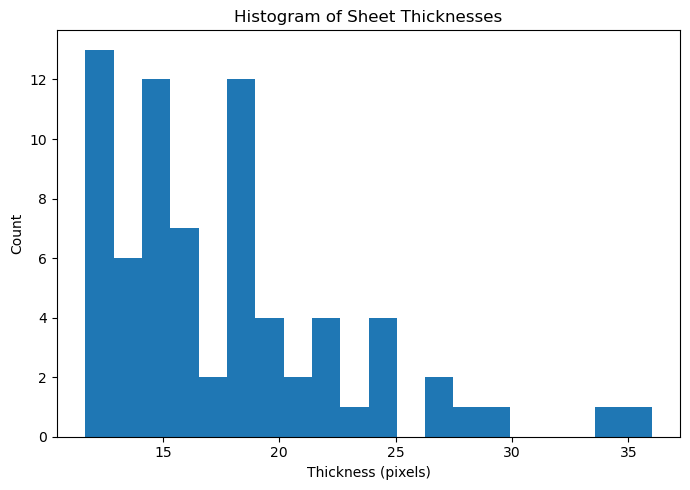

In [13]:
# -----------------------------------------------------
# 1. Label the cleaned mask
# -----------------------------------------------------
labeled_mask = measure.label(cleaned_mask, connectivity=2)
num_regions = labeled_mask.max()
print("Number of connected regions:", num_regions)

# -----------------------------------------------------
# 2. Compute thicknesses
# -----------------------------------------------------
thicknesses = []

min_pixels = 10   # ignore tiny blobs

for label_id in range(1, num_regions + 1):

    region = (labeled_mask == label_id)

    # Skip small regions
    if np.sum(region) < min_pixels:
        continue

    # Euclidean distance transform INSIDE the region
    dist = ndi.distance_transform_edt(region)

    # Full sheet thickness = diameter of largest inscribed circle
    thickness = 2 * dist.max()

    thicknesses.append(thickness)

# -----------------------------------------------------
# 3. Report results
# -----------------------------------------------------
if len(thicknesses) > 0:
    print(f"Found {len(thicknesses)} sheets")
    print(f"Mean thickness = {np.mean(thicknesses):.3f} pixels")
    print(f"Median thickness = {np.median(thicknesses):.3f} pixels")
    print(f"Min thickness = {np.min(thicknesses):.3f} px, Max = {np.max(thicknesses):.3f} px")
else:
    print("No valid sheets found.")

# -----------------------------------------------------
# 4. Histogram of thicknesses
# -----------------------------------------------------
if len(thicknesses) > 0:
    plt.figure(figsize=(7,5))
    plt.hist(thicknesses, bins=20)
    plt.xlabel("Thickness (pixels)")
    plt.ylabel("Count")
    plt.title("Histogram of Sheet Thicknesses")
    plt.tight_layout()
    plt.show()

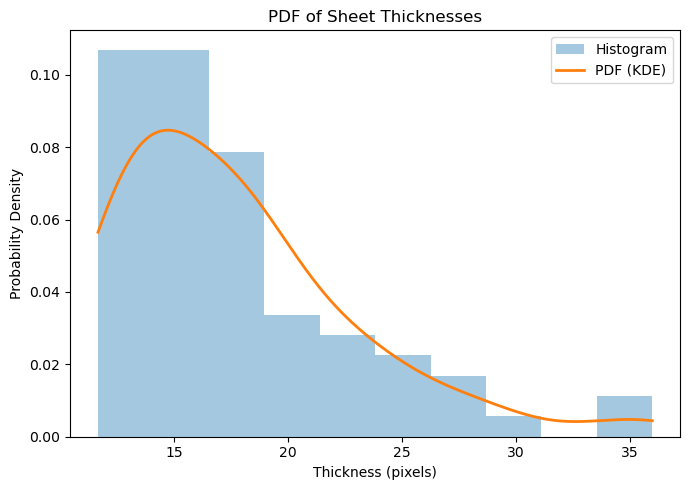

In [17]:
from scipy.stats import gaussian_kde

if len(thicknesses) > 0:
    plt.figure(figsize=(7,5))

    # Histogram (normalized)
    plt.hist(thicknesses, bins=10, density=True, alpha=0.4, label="Histogram")

    # KDE curve
    kde = gaussian_kde(thicknesses)
    xs = np.linspace(min(thicknesses), max(thicknesses), 500)
    plt.plot(xs, kde(xs), linewidth=2, label="PDF (KDE)")

    plt.xlabel("Thickness (pixels)")
    plt.ylabel("Probability Density")
    plt.title("PDF of Sheet Thicknesses")
    plt.legend()
    plt.tight_layout()
    plt.show()

In [2]:
# Compute gradient of J_par field
dJdx, dJdy = np.gradient(J_par)  # assumes unit grid spacing

descent_dirs = []  # (dx, dy) unit vectors

for (x, y) in max_coords:
    gx = dJdx[x, y]
    gy = dJdy[x, y]

    grad = np.array([gx, gy])

    # Avoid division by zero
    if np.allclose(grad, 0):
        descent_dirs.append(np.array([0.0, 0.0]))
        continue

    # Direction of steepest descent = negative normalized gradient
    descent = -grad / np.linalg.norm(grad)
    descent_dirs.append(descent)

NameError: name 'np' is not defined

In [1]:
np.shape(grad)

NameError: name 'np' is not defined

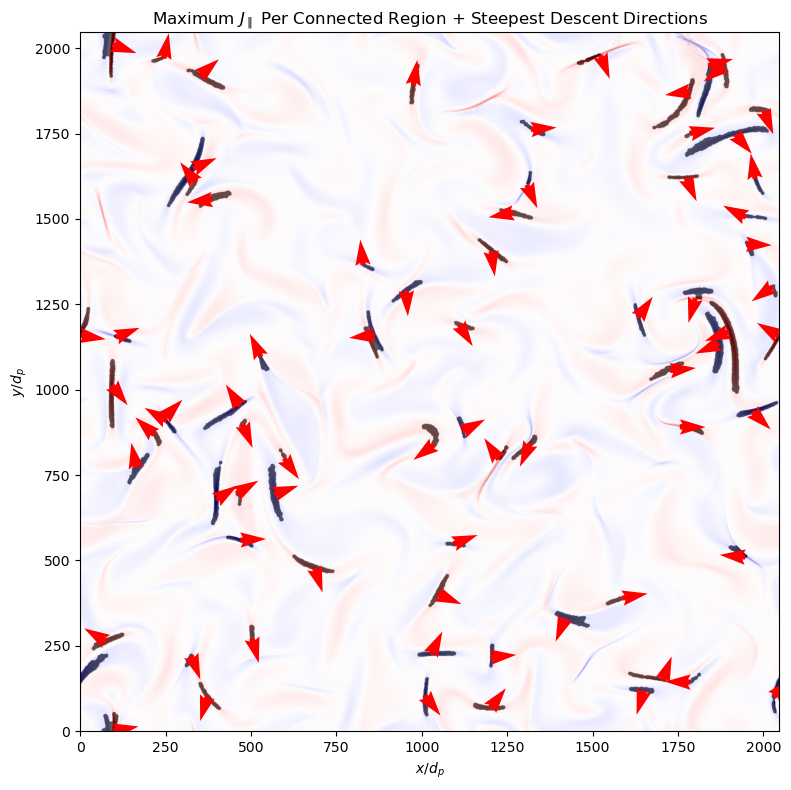

In [29]:
# ---------------------------------------------------------
# PLOT ORIGINAL FIELD + MASK + MAXIMUM POINTS + DESCENT DIRS
# ---------------------------------------------------------
plt.figure(figsize=(10, 8))

plt.imshow(J_par.T, cmap='seismic',
           origin='lower', vmin=-1.5, vmax=1.5)

plt.imshow(~cleaned_mask.T, cmap='gray', alpha=0.6, origin='lower')

# Overlay yellow crosses (max locations)
# for (x, y) in max_coords:
#     plt.plot(x, y, 'x', color='yellow', markersize=8, markeredgewidth=2)

factor = 30.0
# Overlay steepest–descent direction arrows
for (x, y), (dx, dy) in zip(max_coords, descent_dirs):
    plt.quiver(
        x, y, factor*dx, factor*dy,
        color='red',
        angles='xy',
        scale_units='xy',
        scale=0.4,      # adjust arrow length
        width=0.012     # thickness
    )
# Arrow length multiplier


plt.title(r'Maximum $J_\parallel$ Per Connected Region + Steepest Descent Directions')
plt.xlabel(r'$x/d_p$')
plt.ylabel(r'$y/d_p$')

plt.tight_layout()
plt.savefig("Jpar_maxima_with_descent_vectors.png", dpi=300)
plt.show()

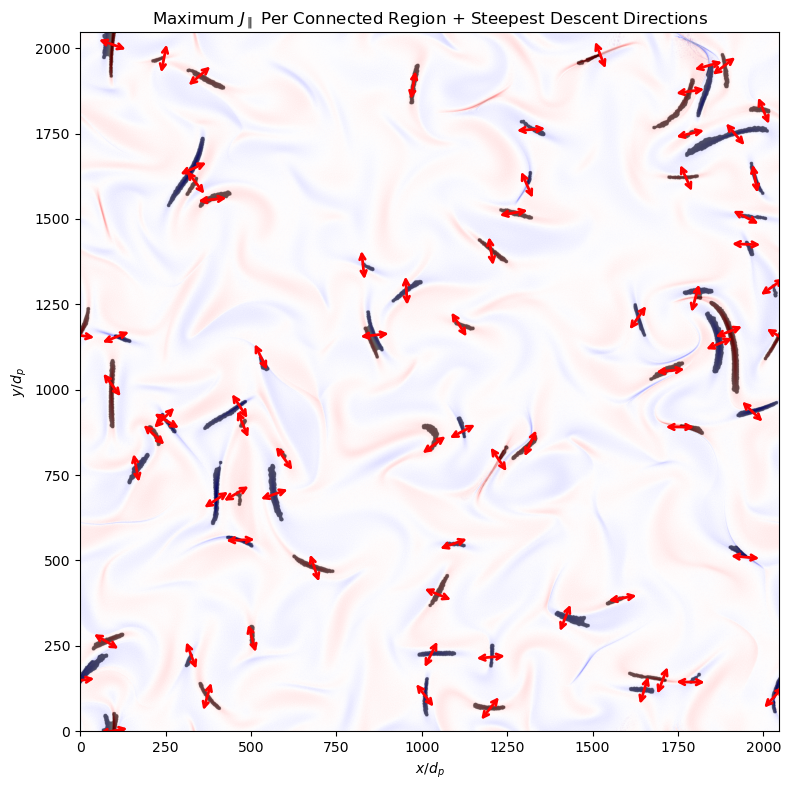

In [35]:
from matplotlib.patches import FancyArrowPatch

plt.figure(figsize=(10, 8))

plt.imshow(J_par.T, cmap='seismic',
           origin='lower', vmin=-1.5, vmax=1.5)

plt.imshow(~cleaned_mask.T, cmap='gray', alpha=0.6, origin='lower')

factor = 100.0

for (x, y), (dx, dy) in zip(max_coords, descent_dirs):
    # Start and end points for symmetric arrow
    start = (x - 0.5 * factor * dx, y - 0.5 * factor * dy)
    end   = (x + 0.5 * factor * dx, y + 0.5 * factor * dy)
    
    arrow = FancyArrowPatch(
        start, end,
        arrowstyle="<->",      # double-ended arrow
        color="red",
        mutation_scale=10,     # controls head size
        linewidth=2,
    )
    plt.gca().add_patch(arrow)

plt.title(r'Maximum $J_\parallel$ Per Connected Region + Steepest Descent Directions')
plt.xlabel(r'$x/d_p$')
plt.ylabel(r'$y/d_p$')

plt.tight_layout()
plt.savefig("Jpar_maxima_with_symmetric_descent_vectors.png", dpi=300)
plt.show()

In [36]:
import numpy as np

distances = []

# Ensure descent_dirs are normalized
descent_dirs = np.array([d/np.linalg.norm(d) for d in descent_dirs])

for (x, y), (dx, dy) in zip(max_coords, descent_dirs):
    x, y = float(x), float(y)  # ensure float for stepping
    step_size = 0.5  # pixel step
    max_steps = 1000  # prevent infinite loop
    
    # Step forward
    xf, yf = x, y
    steps = 0
    while steps < max_steps:
        xf_new = xf + dx*step_size
        yf_new = yf + dy*step_size
        xi, yi = int(round(xf_new)), int(round(yf_new))
        if xi < 0 or yi < 0 or xi >= cleaned_mask.shape[0] or yi >= cleaned_mask.shape[1]:
            break
        if not cleaned_mask[xi, yi]:  # left the connected region
            break
        xf, yf = xf_new, yf_new
        steps += 1
    dist_forward = np.hypot(xf - x, yf - y)

    # Step backward
    xb, yb = x, y
    steps = 0
    while steps < max_steps:
        xb_new = xb - dx*step_size
        yb_new = yb - dy*step_size
        xi, yi = int(round(xb_new)), int(round(yb_new))
        if xi < 0 or yi < 0 or xi >= cleaned_mask.shape[0] or yi >= cleaned_mask.shape[1]:
            break
        if not cleaned_mask[xi, yi]:  # left the connected region
            break
        xb, yb = xb_new, yb_new
        steps += 1
    dist_backward = np.hypot(xb - x, yb - y)

    distances.append((dist_backward, dist_forward))

[(np.float64(11.499999999999977), np.float64(0.49999999999999883)), (np.float64(0.49999999999999417), np.float64(4.499999999999947)), (np.float64(10.500000000000371), np.float64(10.500000000000371)), (np.float64(8.499999999999961), np.float64(9.499999999999956)), (np.float64(25.999999999997964), np.float64(5.499999999999569)), (np.float64(11.99999999999987), np.float64(10.499999999999888)), (np.float64(4.500000000000156), np.float64(9.500000000000329)), (np.float64(18.00000000000005), np.float64(7.50000000000002)), (np.float64(30.500000000000657), np.float64(21.000000000000455)), (np.float64(5.499999999999776), np.float64(2.499999999999898)), (np.float64(2.0000000000001674), np.float64(0.5000000000000419)), (np.float64(6.000000000000127), np.float64(6.000000000000274)), (np.float64(15.49999999999964), np.float64(12.499999999999709)), (np.float64(3.4999999999999774), np.float64(8.999999999999941)), (np.float64(5.500000000000998), np.float64(5.500000000000998)), (np.float64(9.99999999999

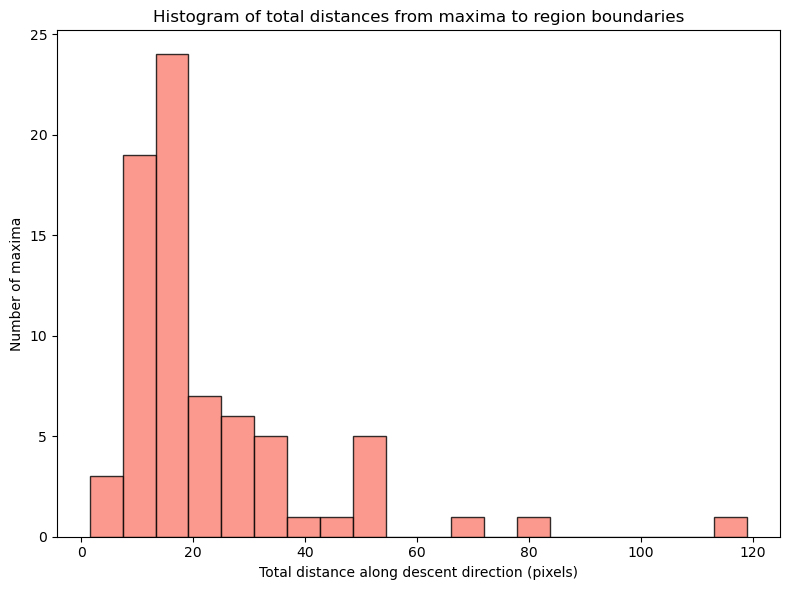

In [38]:
# Calculate total distance for each maximum
total_distances = np.array([d[0] + d[1] for d in distances])

# Plot histogram
plt.figure(figsize=(8, 6))
plt.hist(total_distances, bins=20, color='salmon', edgecolor='black', alpha=0.8)
plt.xlabel('Total distance along descent direction (pixels)')
plt.ylabel('Number of maxima')
plt.title('Histogram of total distances from maxima to region boundaries')
plt.tight_layout()
plt.show()

In [40]:
np.size(total_distances)

74

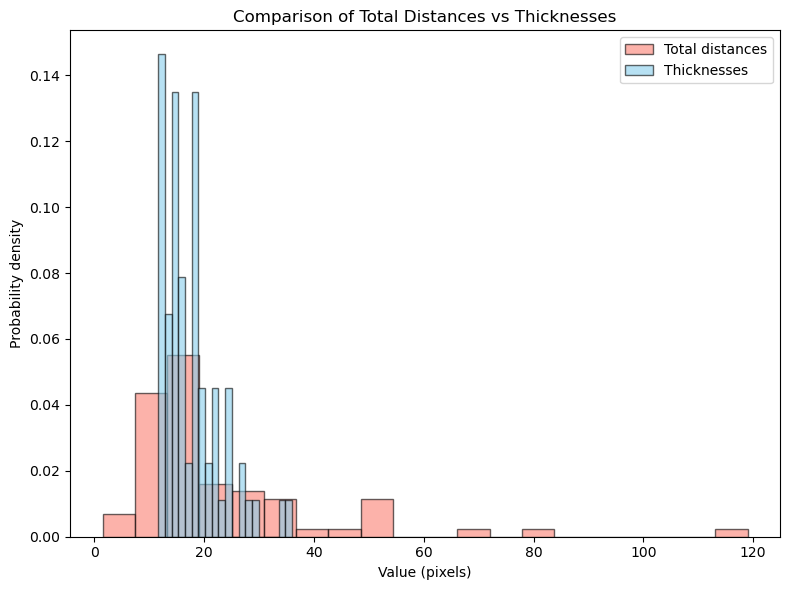

In [42]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(8, 6))

bins = 20  # same bins for both

plt.hist(total_distances, bins=bins, alpha=0.6, label='Total distances',
         color='salmon', edgecolor='black', density=True)
plt.hist(thicknesses, bins=bins, alpha=0.6, label='Thicknesses',
         color='skyblue', edgecolor='black', density=True)

plt.xlabel('Value (pixels)')
plt.ylabel('Probability density')
plt.title('Comparison of Total Distances vs Thicknesses')
plt.legend()
plt.tight_layout()
plt.show()

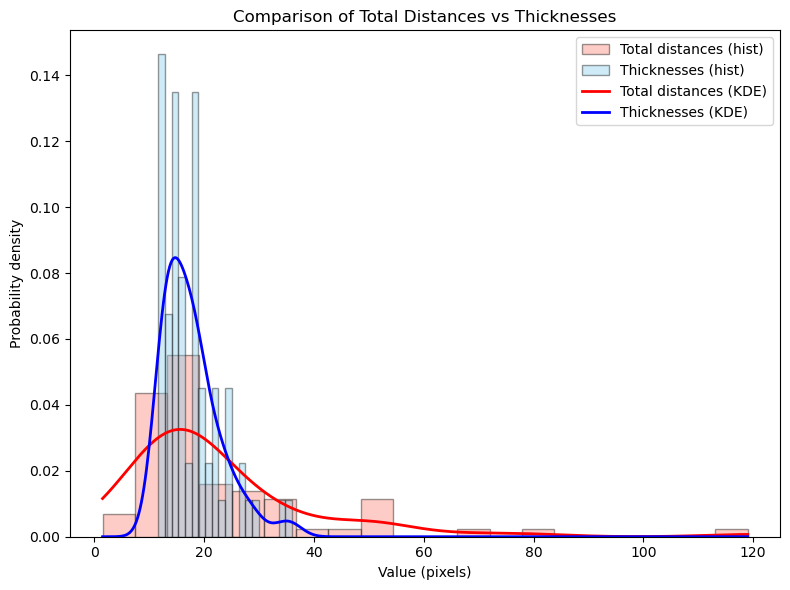

In [44]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import gaussian_kde

total_distances = np.array(total_distances)
thicknesses = np.array(thicknesses)

plt.figure(figsize=(8, 6))

bins = 20  # histogram bins

# --- Plot normalized histograms ---
plt.hist(total_distances, bins=bins, alpha=0.4, label='Total distances (hist)',
         color='salmon', edgecolor='black', density=True)
plt.hist(thicknesses, bins=bins, alpha=0.4, label='Thicknesses (hist)',
         color='skyblue', edgecolor='black', density=True)

# --- Plot smoothed KDE curves ---
x_range = np.linspace(min(total_distances.min(), thicknesses.min()),
                      max(total_distances.max(), thicknesses.max()), 500)

kde_total = gaussian_kde(total_distances)
kde_thick = gaussian_kde(thicknesses)

plt.plot(x_range, kde_total(x_range), color='red', lw=2, label='Total distances (KDE)')
plt.plot(x_range, kde_thick(x_range), color='blue', lw=2, label='Thicknesses (KDE)')

plt.xlabel('Value (pixels)')
plt.ylabel('Probability density')
plt.title('Comparison of Total Distances vs Thicknesses')
plt.legend()
plt.tight_layout()
plt.show()

In [45]:
import numpy as np
from scipy.stats import gaussian_kde

# Convert lists to arrays if not already
total_distances = np.array(total_distances)
thicknesses = np.array(thicknesses)

# Create KDEs
kde_total = gaussian_kde(total_distances)
kde_thick = gaussian_kde(thicknesses)

# Create fine grid to evaluate KDEs
x_range = np.linspace(min(total_distances.min(), thicknesses.min()),
                      max(total_distances.max(), thicknesses.max()), 500)

# Evaluate KDEs
kde_total_values = kde_total(x_range)
kde_thick_values = kde_thick(x_range)

# Find peaks (x value where KDE is maximum)
peak_total = x_range[np.argmax(kde_total_values)]
peak_thick = x_range[np.argmax(kde_thick_values)]

print(f"Peak of total_distances: {peak_total:.2f} pixels")
print(f"Peak of thicknesses: {peak_thick:.2f} pixels")

Peak of total_distances: 15.63 pixels
Peak of thicknesses: 14.69 pixels


In [46]:
def compute_hessian(J, x, y, dx=1.0, dy=1.0):
    """
    Compute 2D Hessian matrix at point (x,y) of array J using central differences.
    """
    d2f_dx2 = (J[y, (x+1)%J.shape[1]] - 2*J[y, x] + J[y, (x-1)%J.shape[1]]) / dx**2
    d2f_dy2 = (J[(y+1)%J.shape[0], x] - 2*J[y, x] + J[(y-1)%J.shape[0], x]) / dy**2
    d2f_dxdy = (
        J[(y+1)%J.shape[0], (x+1)%J.shape[1]] - J[(y+1)%J.shape[0], (x-1)%J.shape[1]]
        - J[(y-1)%J.shape[0], (x+1)%J.shape[1]] + J[(y-1)%J.shape[0], (x-1)%J.shape[1]]
    ) / (4*dx*dy)

    H = np.array([[d2f_dx2, d2f_dxdy],
                  [d2f_dxdy, d2f_dy2]])
    return H

def steepest_descent_direction(J, peaks, dx=1.0, dy=1.0):
    """
    For each peak, compute direction of steepest descent from Hessian.
    
    Parameters
    ----------
    J : 2D array
        J_parallel field
    peaks : list of (y,x) tuples
        Coordinates of detected local maxima
    dx, dy : float
        Grid spacing

    Returns
    -------
    directions : dict
        peak -> (eigenvalue, eigenvector)
    """
    directions = {}
    for (y, x) in peaks:
        H = compute_hessian(J, x, y, dx, dy)
        eigvals, eigvecs = np.linalg.eigh(H)  # sorted eigenvalues
        # largest magnitude eigenvalue
        idx = np.argmax(np.abs(eigvals))
        directions[(y, x)] = (eigvals[idx], eigvecs[:, idx])
    return directions

/tmp/ipykernel_745196/2495173102.py:39: DeprecationWarning: Calling nonzero on 0d arrays is deprecated, as it behaves surprisingly. Use `atleast_1d(cond).nonzero()` if the old behavior was intended. If the context of this warning is of the form `arr[nonzero(cond)]`, just use `arr[cond]`.
  peaks = list(zip(*np.where(max_coords == 1)))


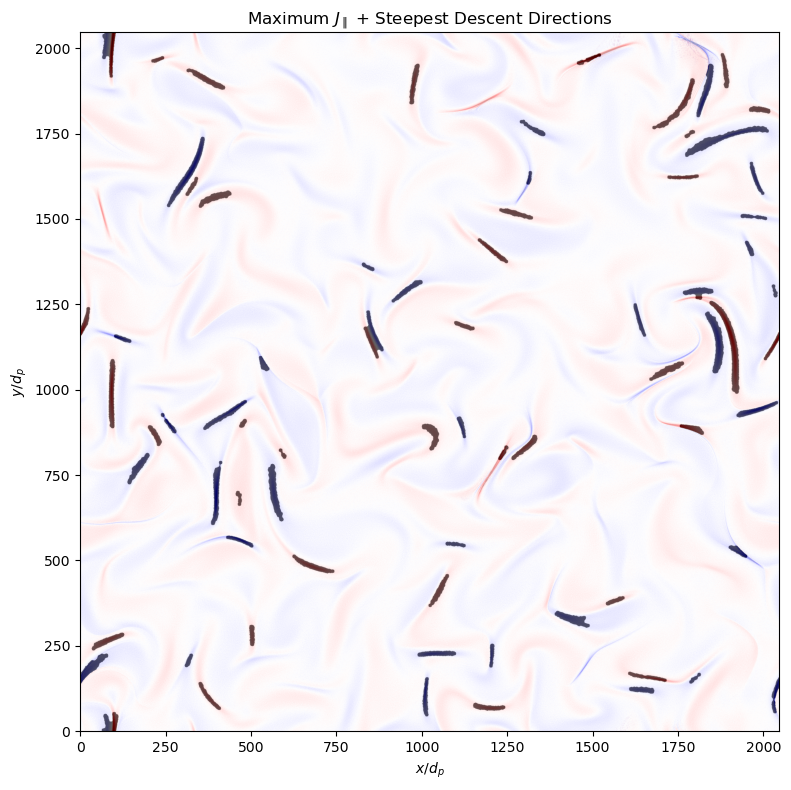

In [48]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch

# -------------------------------
# 1️⃣ Hessian and steepest descent
# -------------------------------
def compute_hessian(J, x, y, dx=1.0, dy=1.0):
    """
    Compute 2D Hessian matrix at point (x,y) of array J using central differences.
    """
    d2f_dx2 = (J[y, (x+1)%J.shape[1]] - 2*J[y, x] + J[y, (x-1)%J.shape[1]]) / dx**2
    d2f_dy2 = (J[(y+1)%J.shape[0], x] - 2*J[y, x] + J[(y-1)%J.shape[0], x]) / dy**2
    d2f_dxdy = (
        J[(y+1)%J.shape[0], (x+1)%J.shape[1]] - J[(y+1)%J.shape[0], (x-1)%J.shape[1]]
        - J[(y-1)%J.shape[0], (x+1)%J.shape[1]] + J[(y-1)%J.shape[0], (x-1)%J.shape[1]]
    ) / (4*dx*dy)

    H = np.array([[d2f_dx2, d2f_dxdy],
                  [d2f_dxdy, d2f_dy2]])
    return H

def steepest_descent_direction(J, peaks, dx=1.0, dy=1.0):
    """
    For each peak, compute direction of steepest descent from Hessian.
    Returns a dict: peak -> (most negative eigenvalue, eigenvector)
    """
    directions = {}
    for (y, x) in peaks:
        H = compute_hessian(J, x, y, dx, dy)
        eigvals, eigvecs = np.linalg.eigh(H)
        idx = np.argmin(eigvals)  # most negative eigenvalue
        directions[(y, x)] = (eigvals[idx], eigvecs[:, idx])
    return directions

# -------------------------------
# 2️⃣ Get peaks
# -------------------------------
peaks = list(zip(*np.where(max_coords == 1)))

# -------------------------------
# 3️⃣ Compute steepest descent directions
# -------------------------------
directions = steepest_descent_direction(J_par, peaks, dx=0.125, dy=0.125)

# -------------------------------
# 4️⃣ Compute distances to connected region boundaries
# -------------------------------
def distance_to_edge(mask, x, y, dx, dy, step_size=0.5, max_steps=1000):
    """Compute distance from (x,y) along (dx,dy) inside mask until boundary."""
    # Forward
    xf, yf = x, y
    steps = 0
    while steps < max_steps:
        xf_new = xf + dx*step_size
        yf_new = yf + dy*step_size
        xi, yi = int(round(xf_new)), int(round(yf_new))
        if xi<0 or yi<0 or xi>=mask.shape[1] or yi>=mask.shape[0]:
            break
        if not mask[yi, xi]:
            break
        xf, yf = xf_new, yf_new
        steps += 1
    dist_forward = np.hypot(xf - x, yf - y)

    # Backward
    xb, yb = x, y
    steps = 0
    while steps < max_steps:
        xb_new = xb - dx*step_size
        yb_new = yb - dy*step_size
        xi, yi = int(round(xb_new)), int(round(yb_new))
        if xi<0 or yi<0 or xi>=mask.shape[1] or yi>=mask.shape[0]:
            break
        if not mask[yi, xi]:
            break
        xb, yb = xb_new, yb_new
        steps += 1
    dist_backward = np.hypot(xb - x, yb - y)

    return dist_backward, dist_forward

# Compute distances for each peak
distances = {}
for (y, x), (eigval, eigvec) in directions.items():
    dx_vec, dy_vec = eigvec
    dist_b, dist_f = distance_to_edge(cleaned_mask, x, y, dx_vec, dy_vec)
    distances[(y, x)] = (dist_b, dist_f)

# -------------------------------
# 5️⃣ Plot symmetric double-headed arrows
# -------------------------------
plt.figure(figsize=(10, 8))
plt.imshow(J_par.T, cmap='seismic', origin='lower', vmin=-1.5, vmax=1.5)
plt.imshow(~cleaned_mask.T, cmap='gray', alpha=0.6, origin='lower')

for (y, x), (eigval, eigvec) in directions.items():
    dx_vec, dy_vec = eigvec
    dist_b, dist_f = distances[(y, x)]
    start = (x - dx_vec * dist_b, y - dy_vec * dist_b)
    end   = (x + dx_vec * dist_f, y + dy_vec * dist_f)
    arrow = FancyArrowPatch(start, end, arrowstyle='<->', color='red', 
                            mutation_scale=10, linewidth=2)
    plt.gca().add_patch(arrow)

plt.title(r'Maximum $J_\parallel$ + Steepest Descent Directions')
plt.xlabel(r'$x/d_p$')
plt.ylabel(r'$y/d_p$')
plt.tight_layout()
plt.show()

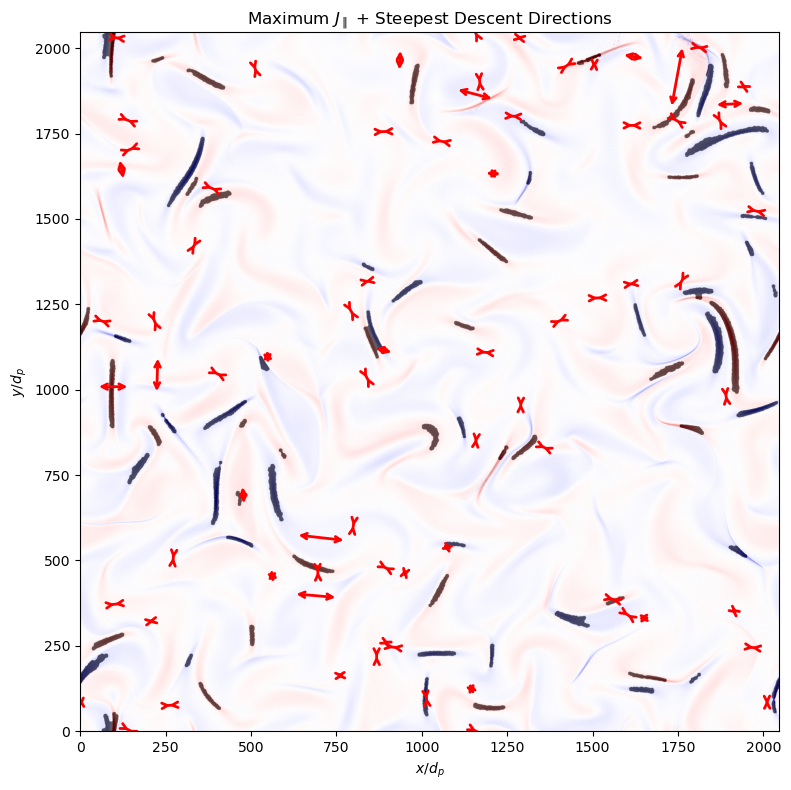

In [49]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch
from scipy.ndimage import label

# ---------------------------------------------------------
# 1️⃣ Compute Hessian
# ---------------------------------------------------------
def compute_hessian(J, x, y, dx=1.0, dy=1.0):
    d2f_dx2 = (J[y, (x+1)%J.shape[1]] - 2*J[y, x] + J[y, (x-1)%J.shape[1]]) / dx**2
    d2f_dy2 = (J[(y+1)%J.shape[0], x] - 2*J[y, x] + J[(y-1)%J.shape[0], x]) / dy**2
    d2f_dxdy = (
        J[(y+1)%J.shape[0], (x+1)%J.shape[1]] - J[(y+1)%J.shape[0], (x-1)%J.shape[1]]
        - J[(y-1)%J.shape[0], (x+1)%J.shape[1]] + J[(y-1)%J.shape[0], (x-1)%J.shape[1]]
    ) / (4*dx*dy)
    return np.array([[d2f_dx2, d2f_dxdy],
                     [d2f_dxdy, d2f_dy2]])

# ---------------------------------------------------------
# 2️⃣ Compute steepest descent directions
# ---------------------------------------------------------
def steepest_descent_direction(J, max_coords, dx=1.0, dy=1.0):
    directions = {}
    for y, x in max_coords:
        H = compute_hessian(J, x, y, dx, dy)
        eigvals, eigvecs = np.linalg.eigh(H)
        idx = np.argmin(eigvals)  # most negative eigenvalue
        directions[(y, x)] = (eigvals[idx], eigvecs[:, idx])
    return directions

# ---------------------------------------------------------
# 3️⃣ Distance to region edges
# ---------------------------------------------------------
def distance_to_edge(mask, x, y, dx, dy, step_size=0.5, max_steps=1000):
    # Forward
    xf, yf = x, y
    steps = 0
    while steps < max_steps:
        xf_new = xf + dx*step_size
        yf_new = yf + dy*step_size
        xi, yi = int(round(xf_new)), int(round(yf_new))
        if xi < 0 or yi < 0 or xi >= mask.shape[1] or yi >= mask.shape[0]:
            break
        if not mask[yi, xi]:
            break
        xf, yf = xf_new, yf_new
        steps += 1
    dist_forward = np.hypot(xf - x, yf - y)

    # Backward
    xb, yb = x, y
    steps = 0
    while steps < max_steps:
        xb_new = xb - dx*step_size
        yb_new = yb - dy*step_size
        xi, yi = int(round(xb_new)), int(round(yb_new))
        if xi < 0 or yi < 0 or xi >= mask.shape[1] or yi >= mask.shape[0]:
            break
        if not mask[yi, xi]:
            break
        xb, yb = xb_new, yb_new
        steps += 1
    dist_backward = np.hypot(xb - x, yb - y)

    return dist_backward, dist_forward

# ---------------------------------------------------------
# 4️⃣ Main workflow
# ---------------------------------------------------------
directions = steepest_descent_direction(J_par, max_coords, dx=0.125, dy=0.125)

distances = {}
for (y, x), (eigval, eigvec) in directions.items():
    dx_vec, dy_vec = eigvec
    dist_b, dist_f = distance_to_edge(cleaned_mask, x, y, dx_vec, dy_vec)
    distances[(y, x)] = (dist_b, dist_f)

# Optional: compute total distances for histograms
total_distances = np.array([d[0]+d[1] for d in distances.values()])

# ---------------------------------------------------------
# 5️⃣ Plot symmetric arrows
# ---------------------------------------------------------
plt.figure(figsize=(10, 8))
plt.imshow(J_par.T, cmap='seismic', origin='lower', vmin=-1.5, vmax=1.5)
plt.imshow(~cleaned_mask.T, cmap='gray', alpha=0.6, origin='lower')

for (y, x), (eigval, eigvec) in directions.items():
    dx_vec, dy_vec = eigvec
    dist_b, dist_f = distances[(y, x)]
    start = (x - dx_vec * dist_b, y - dy_vec * dist_b)
    end   = (x + dx_vec * dist_f, y + dy_vec * dist_f)
    arrow = FancyArrowPatch(start, end, arrowstyle='<->', color='red', 
                            mutation_scale=10, linewidth=2)
    plt.gca().add_patch(arrow)

plt.title(r'Maximum $J_\parallel$ + Steepest Descent Directions')
plt.xlabel(r'$x/d_p$')
plt.ylabel(r'$y/d_p$')
plt.tight_layout()
plt.show()

In [68]:
import numpy as np
from scipy.ndimage import label

# ---------------------------------------------------------
# FUNCTIONS (Hessian + descent direction)
# ---------------------------------------------------------

def compute_hessian(J, x, y, dx=1.0, dy=1.0):
    """
    Compute 2D Hessian matrix at point (x,y) of array J using central differences.
    """
    d2f_dx2 = (J[y, (x+1)%J.shape[1]] - 2*J[y, x] + J[y, (x-1)%J.shape[1]]) / dx**2
    d2f_dy2 = (J[(y+1)%J.shape[0], x] - 2*J[y, x] + J[(y-1)%J.shape[0], x]) / dy**2
    d2f_dxdy = (
        J[(y+1)%J.shape[0], (x+1)%J.shape[1]] - J[(y+1)%J.shape[0], (x-1)%J.shape[1]]
        - J[(y-1)%J.shape[0], (x+1)%J.shape[1]] + J[(y-1)%J.shape[0], (x-1)%J.shape[1]]
    ) / (4*dx*dy)

    H = np.array([[d2f_dx2, d2f_dxdy],
                  [d2f_dxdy, d2f_dy2]])
    return H


def steepest_descent_direction(J, peaks, dx=1.0, dy=1.0):
    """
    For each peak, compute direction of steepest descent from Hessian.
    """
    directions = {}
    for (y, x) in peaks:
        H = compute_hessian(J, x, y, dx, dy)
        eigvals, eigvecs = np.linalg.eigh(H)  

        # Largest magnitude eigenvalue → steepest curvature
        idx = np.argmax(np.abs(eigvals))

        # Descent direction = eigenvector of *negative* curvature
        direction = -np.sign(eigvals[idx]) * eigvecs[:, idx]

        directions[(y, x)] = {
            "eigval": eigvals[idx],
            "eigvec": eigvecs[:, idx],
            "descent_dir": direction
        }

    return directions

# ---------------------------------------------------------
# FIND PEAKS USING CONNECTED REGIONS
# ---------------------------------------------------------

labeled_mask, num_features = label(cleaned_mask)
print("Regions found:", num_features)

peak_coords = []
peak_values = []

for i in range(1, num_features + 1):
    region_mask = (labeled_mask == i)
    region_vals = J_par[region_mask]

    if region_vals.size == 0:
        continue

    max_pos = np.argmax(np.abs(region_vals))
    extreme_value = region_vals[max_pos]
    peak_values.append(extreme_value)

    xs, ys = np.where(region_mask)
    peak_coords.append((xs[max_pos], ys[max_pos]))   # (y,x)

# print("Peak coordinates:", peak_coords)

# ---------------------------------------------------------
# COMPUTE STEEPEST DESCENT DIRECTIONS
# ---------------------------------------------------------

directions = steepest_descent_direction(J_par, peak_coords, 0.0625, 0.0625)

# print("\n--- Steepest descent directions ---")
# for coord, info in directions.items():
#     print(f"Peak at {coord}:")
#     print(f"  Eigenvalue: {info['eigval']}")
#     print(f"  Eigenvector: {info['eigvec']}")
#     print(f"  Descent direction: {info['descent_dir']}\n")

Regions found: 74


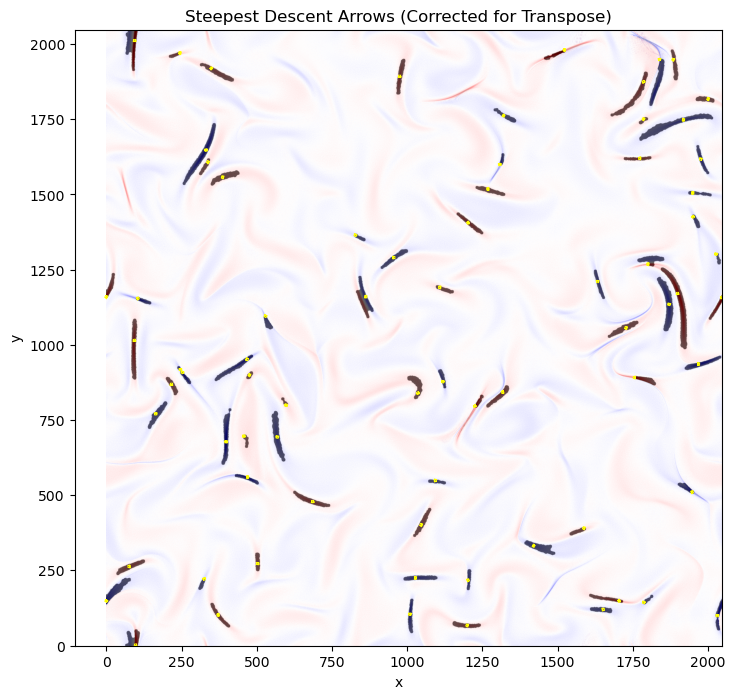

In [69]:
plt.figure(figsize=(10, 8))

plt.imshow(J_par.T, cmap='seismic', origin='lower', vmin=-1.5, vmax=1.5)
plt.imshow(~cleaned_mask.T, cmap='gray', alpha=0.6, origin='lower')

scale = 3.0

for (y, x), info in directions.items():

    # swap coordinates because the image is transposed
    plot_x = y
    plot_y = x

    # swap arrow direction too
    dy, dx = info["descent_dir"]
    dx_plot = dy * scale
    dy_plot = dx * scale

    # arrow
    plt.arrow(
        plot_x, plot_y,
        dx_plot, dy_plot,
        head_width=1.2,
        head_length=1.8,
        fc='yellow',
        ec='yellow',
        linewidth=2,
        length_includes_head=True
    )

plt.title("Steepest Descent Arrows (Corrected for Transpose)")
plt.xlabel("x")
plt.ylabel("y")
plt.show()

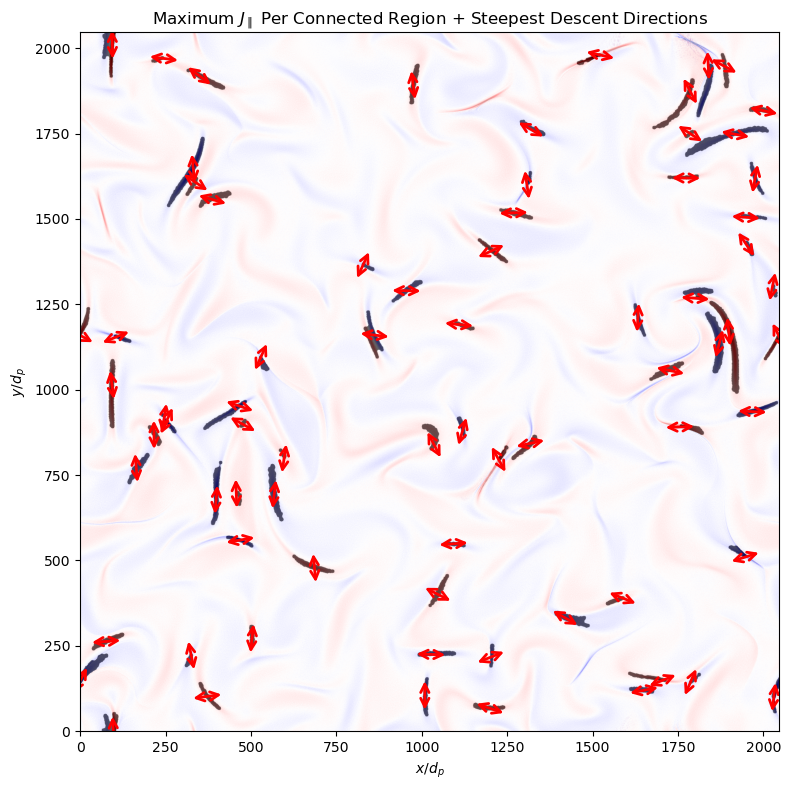

In [70]:
from matplotlib.patches import FancyArrowPatch

plt.figure(figsize=(10, 8))

plt.imshow(J_par.T, cmap='seismic',
           origin='lower', vmin=-1.5, vmax=1.5)

plt.imshow(~cleaned_mask.T, cmap='gray', alpha=0.6, origin='lower')

factor = 100.0  # scale of arrows; adjust visually

ax = plt.gca()

for (y, x), info in directions.items():

    # Descent direction (dy, dx)
    dy, dx = info["descent_dir"]

    # ---- Fix coordinate swap because image is transposed ----
    # J_par.T means:
    #   plotted_x = y
    #   plotted_y = x
    px = y
    py = x

    # Swap direction components too
    dx_plot = dy
    dy_plot = dx

    # Normalize direction to get a stable arrow size
    norm = np.hypot(dx_plot, dy_plot)
    if norm == 0:
        continue

    dx_unit = dx_plot / norm
    dy_unit = dy_plot / norm

    # Compute symmetric endpoints
    start = (px - 0.5 * factor * dx_unit,
             py - 0.5 * factor * dy_unit)
    end   = (px + 0.5 * factor * dx_unit,
             py + 0.5 * factor * dy_unit)

    arrow = FancyArrowPatch(
        start, end,
        arrowstyle="<->",      # double-headed
        color="red",
        mutation_scale=15,     # arrowhead size
        linewidth=2,
    )
    ax.add_patch(arrow)

plt.title(r'Maximum $J_\parallel$ Per Connected Region + Steepest Descent Directions')
plt.xlabel(r'$x/d_p$')
plt.ylabel(r'$y/d_p$')

plt.tight_layout()
plt.savefig("Jpar_maxima_with_symmetric_descent_vectors.png", dpi=300)
plt.show()

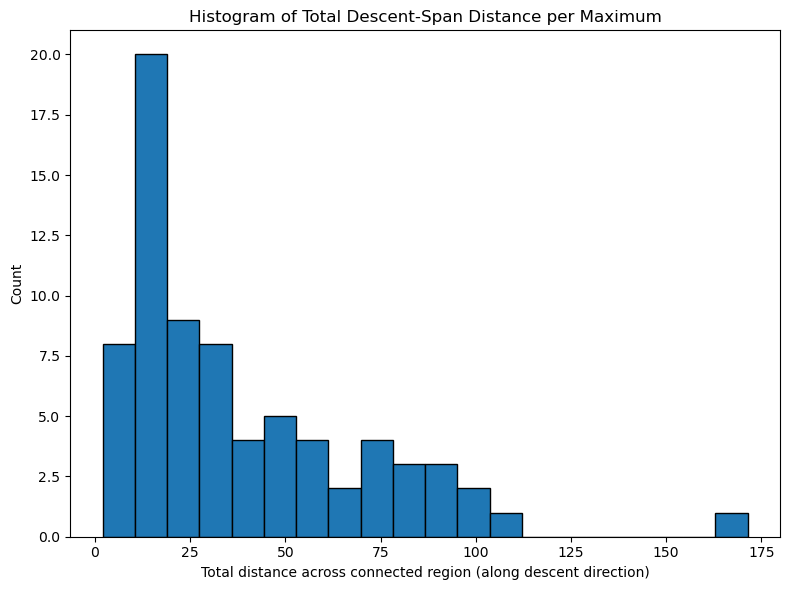

In [76]:
import numpy as np
import matplotlib.pyplot as plt

def distance_to_boundary(cleaned_mask, start_y, start_x, dy, dx, step=0.2, max_steps=5000):
    """
    March from a point in a normalized direction (dy, dx)
    until exiting the connected region defined by cleaned_mask.
    Returns the traveled distance.
    """

    rows, cols = cleaned_mask.shape
    y, x = float(start_y), float(start_x)

    for i in range(max_steps):
        # step forward
        y += dy * step
        x += dx * step

        # stop if outside array
        if x < 0 or x >= cols or y < 0 or y >= rows:
            return i * step
        
        # stop if leaving region
        if not cleaned_mask[int(y), int(x)]:
            return i * step

    return max_steps * step  # fallback (very unlikely)


# ---------------------------------------------------------
# COMPUTE TOTAL BOUNDARY DISTANCE FOR EACH MAXIMUM
# ---------------------------------------------------------

total_distances1 = []

for (y, x), info in directions.items():

    dy, dx = info["descent_dir"]

    # normalize direction
    norm = np.hypot(dx, dy)
    if norm == 0:
        continue

    dy_u = dy / norm
    dx_u = dx / norm

    # forward (+ direction)
    d_forward = distance_to_boundary(cleaned_mask, y, x, dy_u, dx_u)

    # backward (- direction)
    d_backward = distance_to_boundary(cleaned_mask, y, x, -dy_u, -dx_u)

    total_distances1.append(d_forward + d_backward)


# ---------------------------------------------------------
# HISTOGRAM OF TOTAL DISTANCES
# ---------------------------------------------------------

plt.figure(figsize=(8,6))
plt.hist(total_distances1, bins=20, edgecolor="black")
plt.xlabel("Total distance across connected region (along descent direction)")
plt.ylabel("Count")
plt.title("Histogram of Total Descent-Span Distance per Maximum")
plt.tight_layout()
plt.show()

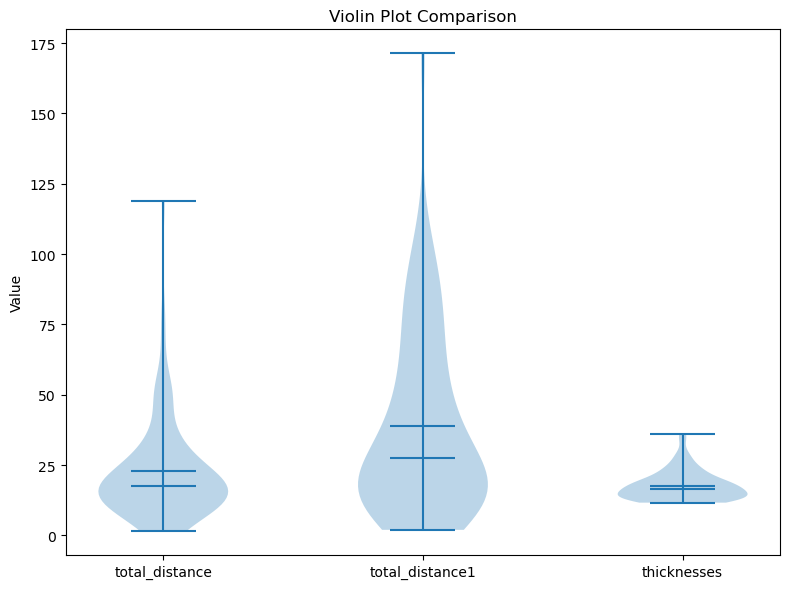

In [79]:
plt.figure(figsize=(8,6))

plt.violinplot([total_distances, total_distances1, thicknesses],
               showmeans=True, showmedians=True)

plt.xticks([1,2,3], ["total_distance", "total_distance1", "thicknesses"])
plt.ylabel("Value")
plt.title("Violin Plot Comparison")
plt.tight_layout()
plt.show()

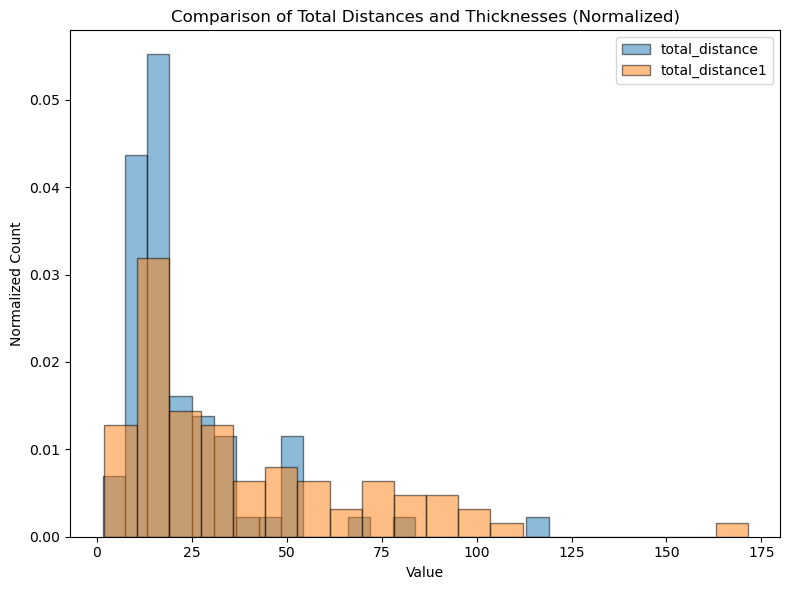

In [83]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))

plt.hist(total_distances, bins=20, alpha=0.5, label="total_distance", edgecolor='black', density=True)
plt.hist(total_distances1, bins=20, alpha=0.5, label="total_distance1", edgecolor='black', density=True)
# plt.hist(thicknesses, bins=20, alpha=0.5, label="thicknesses", edgecolor='black', density=True)

plt.xlabel("Value")
plt.ylabel("Normalized Count")
plt.title("Comparison of Total Distances and Thicknesses (Normalized)")
plt.legend()
plt.tight_layout()
plt.show()